# Baselines

Simple models to compare with LightGBM: logistic regression, then a random forest. Same time split and the same
features as in `03_features.ipynb`. For reference, a model that knows nothing gets ROC-AUC 0.5 and a PR-AUC equal
to the fraud share (0.034 on valid).

In [25]:
from sklearn.metrics import roc_auc_score, average_precision_score

from fraud.data import load_train
from fraud.features import add_features
from fraud.split import time_split

In [26]:
df = add_features(load_train())
train, valid, _ = time_split(df)

NON_FEATURES = ["isFraud", "TransactionDT", "TransactionID"]
X_train, y_train = train.drop(columns=NON_FEATURES), train["isFraud"]
X_valid, y_valid = valid.drop(columns=NON_FEATURES), valid["isFraud"]

In [27]:
print(X_train.dtypes.astype(str).value_counts())
print("columns with missing values:", X_train.isna().any().sum())

float32     398
category     31
float64      10
int16         1
Name: count, dtype: int64
columns with missing values: 380


In [28]:
LR_COLS = [c for c in X_train.columns if not c.startswith("V")]
CAT_COLS = X_train[LR_COLS].select_dtypes("category").columns.tolist()
NUM_COLS = [c for c in LR_COLS if c not in CAT_COLS]

print(len(LR_COLS), "columns:", len(NUM_COLS), "numeric,", len(CAT_COLS), "categorical")

101 columns: 70 numeric, 31 categorical


In [29]:
X_train[CAT_COLS].nunique().sort_values(ascending=False)

DeviceInfo       1546
id_33             183
id_31             108
id_30              71
R_emaildomain      60
P_emaildomain      59
ProductCD           5
card6               4
card4               4
id_34               4
id_15               3
M4                  3
id_23               3
M2                  2
M1                  2
id_12               2
M9                  2
M8                  2
M7                  2
M6                  2
M5                  2
M3                  2
id_27               2
id_28               2
id_29               2
id_16               2
id_35               2
id_36               2
id_37               2
id_38               2
DeviceType          2
dtype: int64

In [30]:
counts = X_train["DeviceInfo"].value_counts()
frequent = counts[counts >= 100]

print(len(frequent), "values with 100+ transactions")
print(f"they cover {frequent.sum() / counts.sum():.0%} of the rows where DeviceInfo is filled")

36 values with 100+ transactions
they cover 84% of the rows where DeviceInfo is filled


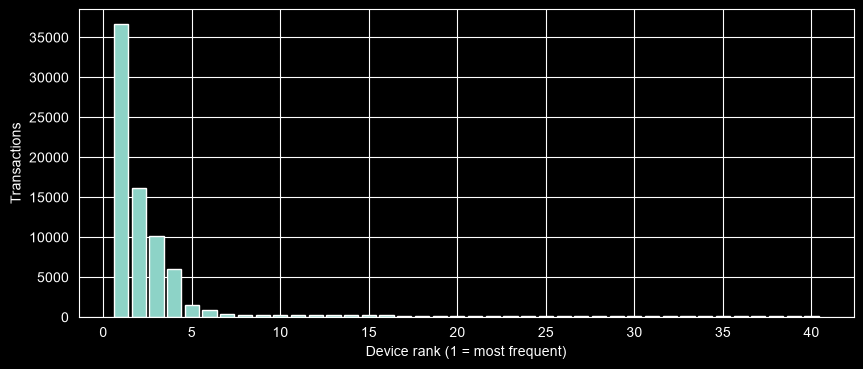

In [31]:
import matplotlib.pyplot as plt

coverage = counts[counts > 0].cumsum() / counts.sum() * 100

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(1, 41), counts.head(40).to_numpy())
ax.set_xlabel("Device rank (1 = most frequent)")
ax.set_ylabel("Transactions")
plt.show()

Turning each category into 0/1 columns, one per value, would give about 2,100 columns, three quarters of them from
`DeviceInfo` (1,546 devices in train). Most devices are rare: only 36 have 100 or more transactions, and they cover
84% of the rows where the device is filled; the first four alone cover about three quarters. A device seen a few
times gives the model an unreliable weight, and new devices appear in valid, so values with fewer than 100
transactions in train are merged into one "other" value.

In [32]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(min_frequency=100, handle_unknown="infrequent_if_exist")
encoder.fit(X_train[CAT_COLS])

cat_train = encoder.transform(X_train[CAT_COLS])
cat_valid = encoder.transform(X_valid[CAT_COLS])
print('train shape:', cat_train.shape)
print('valid shape:', cat_valid.shape)

train shape: (414542, 334)
valid shape: (83571, 334)


`OneHotEncoder` learns, on train only, which values of each category column have at least 100 transactions; each
of them gets its own 0/1 column, and all other values, including values never seen in train, share one "other"
column. Missing values get their own column too, since missingness is informative. The 31 category columns become
334 columns instead of about 2,100, and valid gets exactly the same 334 columns, because the model learns one
weight per column.

In [33]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median",add_indicator=True)
imputer.fit(X_train[NUM_COLS])

num_train = imputer.transform(X_train[NUM_COLS])
num_valid = imputer.transform(X_valid[NUM_COLS])
print('train shape:', num_train.shape)
print('valid shape:', num_valid.shape)

train shape: (414542, 124)
valid shape: (83571, 124)


Logistic regression cannot use missing values, so `SimpleImputer` fills them with the column median learned on train
(the median is not pulled up by very large values, unlike the mean). Filling alone would hide which fields were
empty, and missingness predicts fraud, so each column that has missing values in train also gets a 0/1 "was
missing" flag. The 70 numeric columns become 124: 54 columns get a flag, and 16 have no missing values at all
(`TransactionAmt`, `card1`, `C1`-`C14`).

In [34]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(num_train)

num_train_scaled = scaler.transform(num_train)
num_valid_scaled = scaler.transform(num_valid)

In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

numeric = Pipeline([
    ('imputer', SimpleImputer(strategy="median",add_indicator=True)),
    ('scaler', StandardScaler()),
])

preprocess = ColumnTransformer([
    ('num', numeric, NUM_COLS),
    ('cat', OneHotEncoder(min_frequency=100, handle_unknown="infrequent_if_exist"), CAT_COLS),
])

logreg = Pipeline([
    ('preprocessor', preprocess),
    ('classifier', LogisticRegression(max_iter=1000)),
])

In [36]:
logreg.fit(X_train, y_train)
scores = logreg.predict_proba(X_valid)[:, 1]

print(f"ROC-AUC {roc_auc_score(y_valid, scores):.4f}   PR-AUC {average_precision_score(y_valid, scores):.4f}")

ROC-AUC 0.8201   PR-AUC 0.2998


Logistic regression on the 101 non-`V` columns (458 after preparation) reaches ROC-AUC 0.820 and PR-AUC 0.300 on
valid: about 9 times the floor of 0.034, but half of LightGBM's 0.607. A linear model adds up one weight per column,
so it cannot learn combinations such as "small amounts are risky only for product `C`". It also reads number-coded
columns such as `card1`, `addr1` and `card_start_day` as amounts, although they are codes, while trees split them
into narrow ranges and so recognise cards and clients. And it does not see the 339 `V` columns.

In [37]:
import lightgbm as lgb

MODEL_PARAMS = dict(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=63,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.5,
    n_jobs=8,
    verbose=-1,
)

for seed in [42, 1, 2]:
    model = lgb.LGBMClassifier(**MODEL_PARAMS,random_state=seed)
    model.fit(X_train[LR_COLS], y_train)
    scores = model.predict_proba(X_valid[LR_COLS])[:, 1]
    print(f"seed {seed:<3} ROC-AUC {roc_auc_score(y_valid, scores):.4f}   PR-AUC {average_precision_score(y_valid, scores):.4f}")

seed 42  ROC-AUC 0.9233   PR-AUC 0.5960
seed 1   ROC-AUC 0.9258   PR-AUC 0.5940
seed 2   ROC-AUC 0.9256   PR-AUC 0.5911


For a fair comparison, LightGBM is trained on the same 101 non-`V` columns: PR-AUC 0.5960, 0.5940 and 0.5911 over
seeds 42, 1, 2 (mean 0.594, ROC-AUC 0.925), against 0.607 with all 440 columns. The 339 `V` columns add only
0.013, so almost the whole gap to logistic regression (0.300) comes from the model itself, not from the columns.